In [1]:
main_dir = "/home/gap2/Downloads/PPRL-Dev-main/results/random_configurations/"
datasets= ["D2", "D3", "D4", "D8", "D9", "D10"]

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PRECISION = "Precision %"
RECALL = "Recall %"

def pareto_front(df, recall_threshold=85):
    # Keep only rows above the recall threshold
    df = df[df[RECALL] > recall_threshold]
    
    # Sort by precision (descending)
    df = df.sort_values(PRECISION, ascending=False)

    best_recall = -np.inf
    keep = []

    for idx, row in df.iterrows():
        if row[RECALL] > best_recall:
            keep.append(idx)
            best_recall = row[RECALL]

    return df.loc[keep].sort_values(PRECISION)

In [3]:
from numpy import trapz

def hypervolume(front):

    front = front.sort_values(PRECISION)

    return trapz(
        front[RECALL],
        front[PRECISION]
    )

In [4]:
def dominates(a, b):
    return (
        a[PRECISION] >= b[PRECISION]
        and a[RECALL] >= b[RECALL]
        and (
            a[PRECISION] > b[PRECISION]
            or a[RECALL] > b[RECALL]
        )
    )


def dominance_count(frontA, frontB):
    count = 0

    for _, pointB in frontB.iterrows():
        for _, pointA in frontA.iterrows():
            if dominates(pointA, pointB):
                count += 1
                break

    return count


def dominance_percentage(frontA, frontB):
    n = len(frontB)
    if n == 0:
        return 0.0

    return 100.0 * dominance_count(frontA, frontB) / n






D2


/tmp/ipykernel_17618/1178662364.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


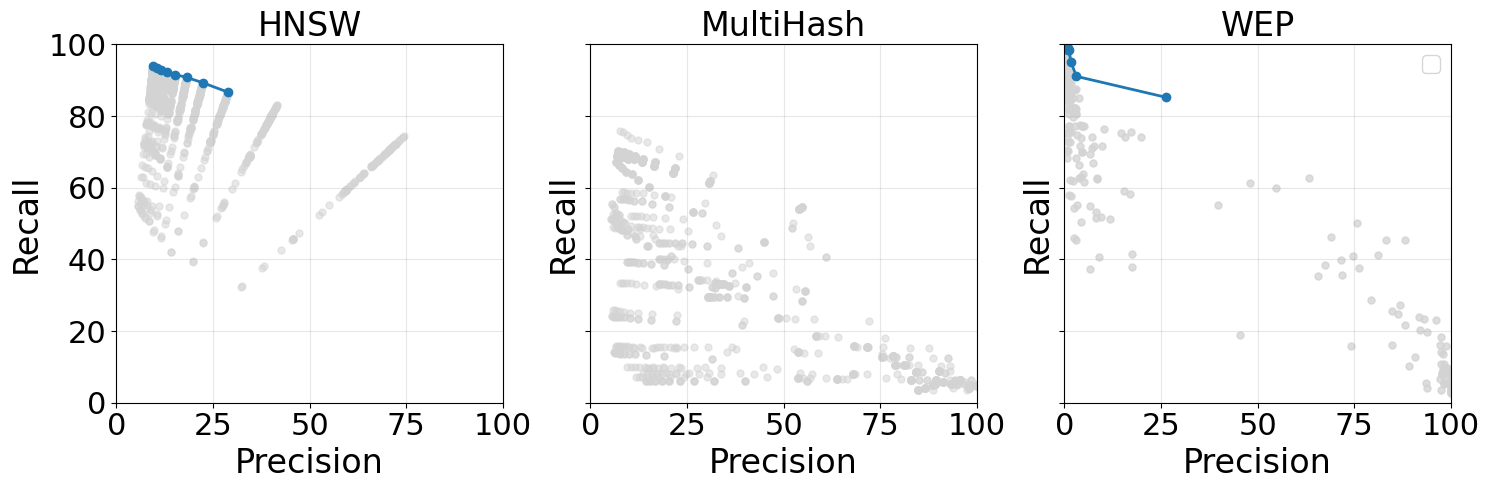

/tmp/ipykernel_17618/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_17618/1178662364.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


HNSW 1760.2786500000002
MultiHash 0.0
WEP 2245.54305
           HNSW MultiHash    WEP
HNSW          -      0.0%  28.6%
MultiHash  0.0%         -   0.0%
WEP        0.0%      0.0%      -





D3


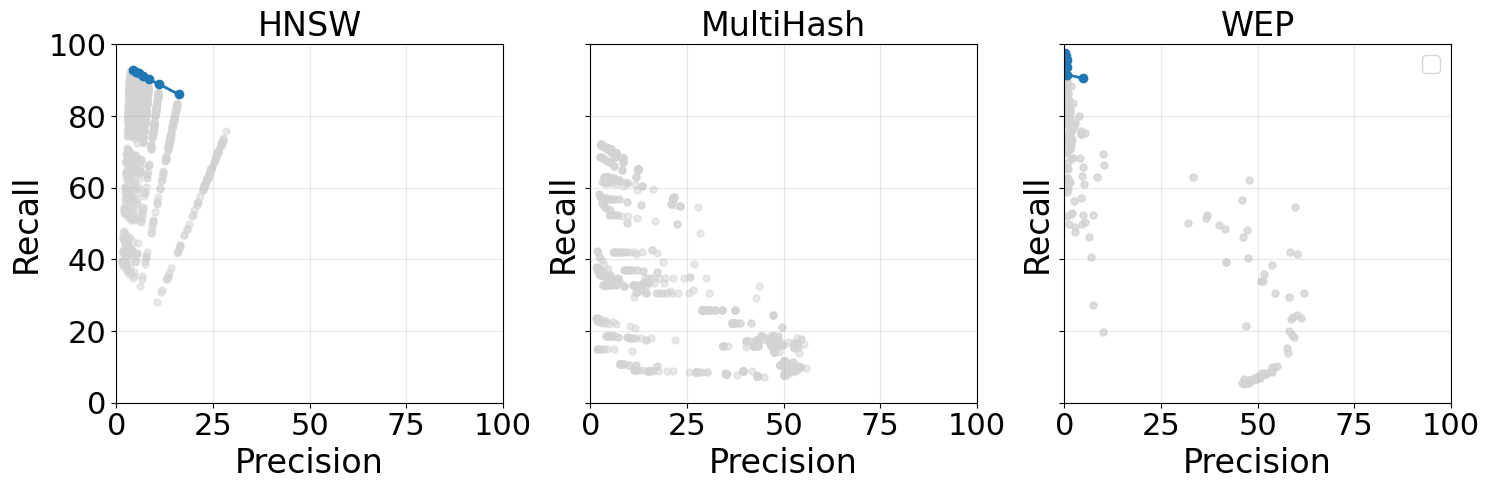

/tmp/ipykernel_17618/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_17618/1178662364.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


HNSW 1052.9933999999998
MultiHash 0.0
WEP 426.3925500000001
           HNSW MultiHash    WEP
HNSW          -      0.0%  33.3%
MultiHash  0.0%         -   0.0%
WEP        0.0%      0.0%      -





D4


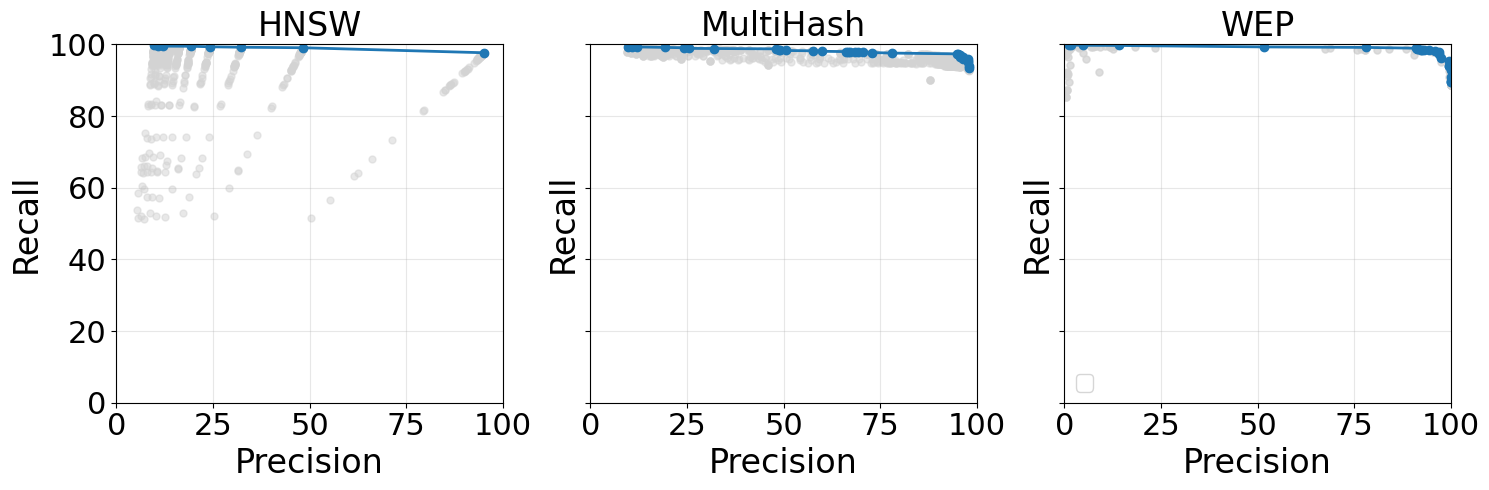

/tmp/ipykernel_17618/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_17618/1178662364.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


HNSW 8439.8704
MultiHash 8673.097049999998
WEP 9793.41475
            HNSW MultiHash   WEP
HNSW           -     34.4%  0.0%
MultiHash   0.0%         -  0.0%
WEP        75.0%     96.9%     -





D8


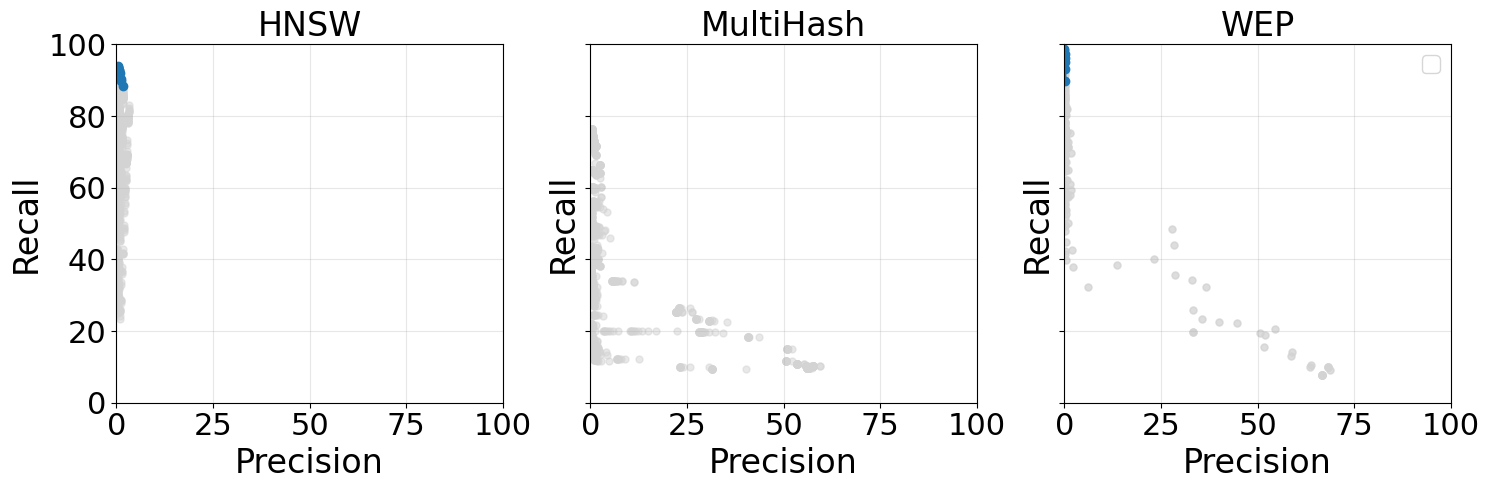

/tmp/ipykernel_17618/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_17618/1178662364.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


HNSW 119.14665
MultiHash 0.0
WEP 17.7795
           HNSW MultiHash    WEP
HNSW          -      0.0%  28.6%
MultiHash  0.0%         -   0.0%
WEP        0.0%      0.0%      -





D9


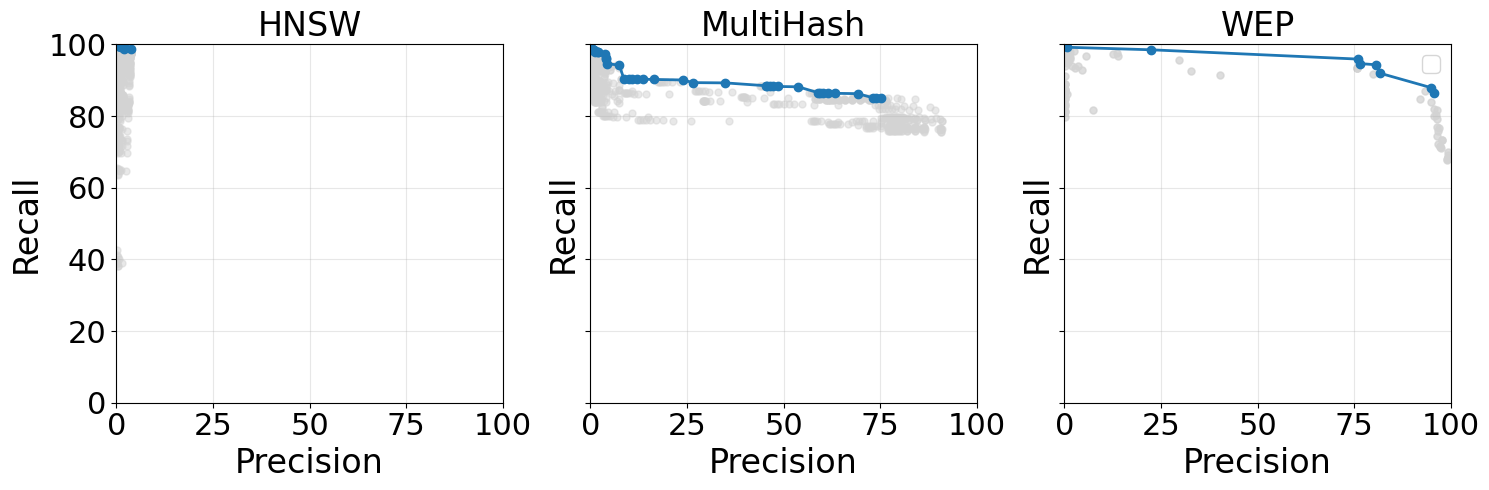

/tmp/ipykernel_17618/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(
/tmp/ipykernel_17618/1178662364.py:57: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16)


HNSW 326.21155
MultiHash 6671.96795
WEP 9201.203400000002
           HNSW MultiHash    WEP
HNSW          -     28.2%  15.4%
MultiHash  0.0%         -   0.0%
WEP        0.0%    100.0%      -





D10


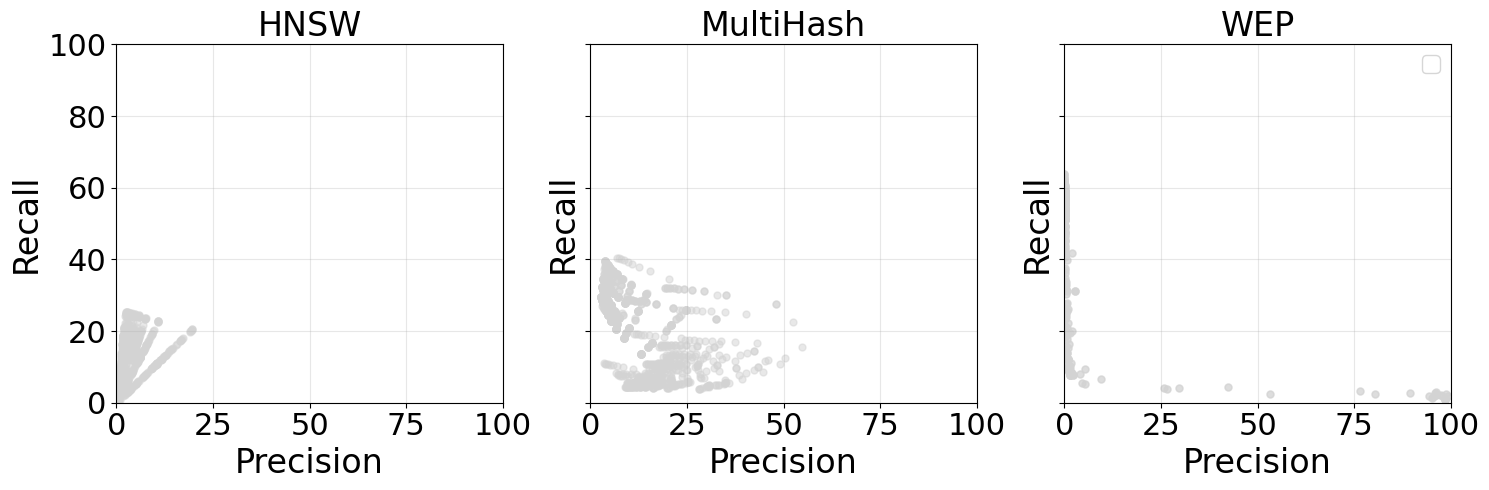

HNSW 0.0
MultiHash 0.0
WEP 0.0
           HNSW MultiHash   WEP
HNSW          -      0.0%  0.0%
MultiHash  0.0%         -  0.0%
WEP        0.0%      0.0%     -


/tmp/ipykernel_17618/2420799314.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return trapz(


In [5]:
for dataset in datasets:
    print("\n\n\n\n\n" + dataset)
    
    files = {
        #"Flat": main_dir + dataset + "/faiss_flat.csv",
        "HNSW": main_dir + "faiss/" +  dataset + "/faiss_hnsw.csv",
        "MultiHash": main_dir + "faiss/" +  dataset + "/faiss_multihash.csv",
        "WEP": main_dir + "metablocking/" + dataset + "/WeightedEdgePruning.csv"
    }

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 5),
        sharex=True,
        sharey=True
    )

    pareto = {} 
    for ax, (title, filename) in zip(axes, files.items()):

        df = pd.read_csv(filename)
        pf = pareto_front(df)
        pareto[title] = pf
        
        # All experiments
        ax.scatter(
            df[PRECISION],
            df[RECALL],
            color="lightgray",
            alpha=0.5,
            s=25
        )

        # Pareto front
        ax.plot(
            pf[PRECISION],
            pf[RECALL],
            "-o",
            linewidth=2,
            markersize=6
        )

        ax.set_title(title, fontsize=24)
        ax.set_xlabel("Precision", fontsize=24)
        ax.set_ylabel("Recall", fontsize=24)
        ax.tick_params(axis='both', labelsize=22)

        ax.grid(alpha=0.3)
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)

    axes[0].set_ylabel("Recall")

    for ax in axes:
        ax.set_xlabel("Precision")
        
    ax.legend(fontsize=16)

    plt.tight_layout()
    plt.show()
    
    for name, pf in pareto.items():
        print(name, hypervolume(pf)) #higher is better
        
    names = list(pareto.keys())

    table = pd.DataFrame(
        index=names,
        columns=names
    )

    for A in names:
        for B in names:

            if A == B:
                table.loc[A,B] = "-"

            else:
                table.loc[A, B] = f"{dominance_percentage(pareto[A], pareto[B]):.1f}%"

    print(table)

In [6]:
from IPython.display import display, HTML

for dataset in datasets:
    all_summaries = []
    print("\n\n\n" + dataset)
    for threshold in [85, 90, 95]:
        files = {
            "HNSW": main_dir + "faiss/" +  dataset + "/faiss_hnsw.csv",
            "MultiHash": main_dir + "faiss/" +  dataset + "/faiss_multihash.csv",
            "WEP": main_dir + "metablocking/" + dataset + "/WeightedEdgePruning.csv"
        }

        for name, filename in files.items():
            df = pd.read_csv(filename)
            valid = df[df["Recall %"] >= threshold]

            if valid.empty:
                continue

            best = valid.loc[valid["Precision %"].idxmax()].to_dict()
            best["Method"] = name
            best["Dataset"] = dataset

            all_summaries.append(best)

        summary_df = pd.DataFrame(all_summaries)

    display(
        HTML(
            f"""
            <div style="overflow-x:auto; width:100%;">
                {pd.DataFrame(all_summaries).to_html()}
            </div>
            """
        )
    )




D2


,name,candidate_pairs,M,top_k,index_runtime,blocking_runtime,runtime,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,weighting_scheme,lsh_config,filtering_config
0,FAISS HNSW Blocking,3192,32.0,3.0,0.01,0.01,0.02,28.88,86.65,43.33,922,2270,934,142,"{'attributes': ['name'], 'size': 1024, 'offset': 0, 'num_hashes': 9, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",HNSW,D2,NaN,NaN,NaN
1,Weighted Edge Pruning,3463,NaN,NaN,NaN,NaN,0.04,26.19,85.24,40.07,907,2556,919,157,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D2,CN-CBS,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.2}"
2,FAISS HNSW Blocking,5320,32.0,5.0,0.01,0.02,0.03,18.16,90.79,30.26,966,4354,978,98,"{'attributes': ['name'], 'size': 1024, 'offset': 0, 'num_hashes': 15, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",HNSW,D2,NaN,NaN,NaN
3,Weighted Edge Pruning,31378,NaN,NaN,NaN,NaN,0.09,3.09,91.07,5.97,969,30409,981,95,"{'attributes': ['name'], 'size': 512, 'offset': 0, 'num_hashes': 3, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D2,CN-CBS,"{'psi': 9, 'lambda': 134, 'distance_threshold': 204}","{'method': 'Block Filtering', 'ratio': 0.4}"
4,WeightedEdgePruning,61391,NaN,NaN,NaN,NaN,0.12,1.65,95.21,3.24,1013,60378,1025,51,"{'attributes': ['name'], 'size': 256, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D2,CN-CBS,"{'psi': 19, 'lambda': 125, 'distance_threshold': 51}","{'method': 'Block Purging', 'smoothing_factor': 0.9}"





D3


,name,candidate_pairs,M,top_k,index_runtime,blocking_runtime,runtime,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,weighting_scheme,lsh_config,filtering_config
0,FAISS HNSW Blocking,5870,64.0,2.0,0.02,0.03,0.05,16.15,86.03,27.19,948,4922,3033,154,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 6, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",HNSW,D3,NaN,NaN,NaN
1,Weighted Edge Pruning,20327,NaN,NaN,NaN,NaN,0.10,4.90,90.47,9.31,997,19330,3082,105,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D3,CN-CBS,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}"
2,FAISS HNSW Blocking,11740,64.0,4.0,0.02,0.04,0.06,8.47,90.20,15.48,994,10746,3079,108,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 6, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",HNSW,D3,NaN,NaN,NaN
3,Weighted Edge Pruning,20327,NaN,NaN,NaN,NaN,0.10,4.90,90.47,9.31,997,19330,3082,105,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D3,CN-CBS,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Filtering', 'ratio': 0.5}"
4,Weighted Edge Pruning,177442,NaN,NaN,NaN,NaN,0.27,0.59,95.64,1.18,1054,176388,3139,48,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 4, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D3,CN-CBS,"{'psi': 12, 'lambda': 115, 'distance_threshold': 307}","{'method': 'Block Filtering', 'ratio': 0.6}"





D4


...

,name,candidate_pairs,M,top_k,index_runtime,blocking_runtime,runtime,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,weighting_scheme,lsh_config,filtering_config
0,FAISS HNSW Blocking,44136,64.0,2.0,0.03,0.20,0.23,1.71,88.51,3.36,755,43381,23671,98,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 3, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",HNSW,D8,NaN,NaN,NaN
1,Weighted Edge Pruning,386928,NaN,NaN,NaN,NaN,0.77,0.20,89.80,0.40,766,386162,23682,87,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 2}",WEP,D8,CN-CBS,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.5}"
2,FAISS HNSW Blocking,66204,64.0,3.0,0.03,0.26,0.29,1.16,90.27,2.30,770,65434,23686,83,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 3, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",HNSW,D8,NaN,NaN,NaN
3,WeightedEdgePruning,727351,NaN,NaN,NaN,NaN,1.68,0.11,93.08,0.22,794,726557,23710,59,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D8,CN-CBS,"{'psi': 40, 'lambda': 137, 'distance_threshold': 51}","{'method': 'Block Purging', 'smoothing_factor': 0.9}"
4,Weighted Edge Pruning,1399987,NaN,NaN,NaN,NaN,2.19,0.06,95.08,0.12,811,1399176,23727,42,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 4, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",WEP,D8,CN-CBS,"{'psi': 12, 'lambda': 115, 'distance_threshold': 307}","{'method': 'Block Filtering', 'ratio': 0.6}"





D9


,name,candidate_pairs,M,top_k,index_runtime,blocking_runtime,runtime,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,config,Method,Dataset,weighting_scheme,lsh_config,filtering_config
0,FAISS HNSW Blocking,61350,64.0,1.0,0.04,0.51,0.55,3.71,98.74,7.15,2275,59075,61493,29,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 4, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",HNSW,D9,NaN,NaN,NaN
1,FAISS MULTIHASH Blocking,2605,NaN,4.0,0.03,0.24,0.28,75.20,85.03,79.81,1959,646,61177,345,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 4, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",MultiHash,D9,NaN,NaN,NaN
2,Weighted Edge Pruning,2086,NaN,NaN,NaN,NaN,0.80,95.54,86.50,90.80,1993,93,61211,311,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 9, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D9,CN-CBS,"{'psi': 19, 'lambda': 125, 'distance_threshold': 102}","{'method': 'Block Filtering', 'ratio': 0.3}"
3,FAISS HNSW Blocking,61350,64.0,1.0,0.04,0.51,0.55,3.71,98.74,7.15,2275,59075,61493,29,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 4, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",HNSW,D9,NaN,NaN,NaN
4,FAISS MULTIHASH Blocking,8660,NaN,1.0,0.02,0.26,0.28,23.96,90.06,37.85,2075,6585,61293,229,"{'attributes': ['title'], 'size': 256, 'offset': 0, 'num_hashes': 2, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 4}",MultiHash,D9,NaN,NaN,NaN
5,WeightedEdgePruning,2593,NaN,NaN,NaN,NaN,0.37,81.68,91.93,86.50,2118,475,61336,186,"{'attributes': ['title'], 'size': 64, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D9,CN-CBS,"{'psi': 21, 'lambda': 146, 'distance_threshold': 12}","{'method': 'Block Purging', 'smoothing_factor': 0.9}"
6,FAISS HNSW Blocking,61350,64.0,1.0,0.04,0.51,0.55,3.71,98.74,7.15,2275,59075,61493,29,"{'attributes': ['title'], 'size': 512, 'offset': 0, 'num_hashes': 4, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",HNSW,D9,NaN,NaN,NaN
7,FAISS MULTIHASH Blocking,54886,NaN,1.0,0.02,0.38,0.40,4.03,95.92,7.73,2210,52676,61428,94,"{'attributes': ['title'], 'size': 128, 'offset': 0, 'num_hashes': 1, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",MultiHash,D9,NaN,NaN,NaN
8,Weighted Edge Pruning,2905,NaN,NaN,NaN,NaN,0.58,76.04,95.88,84.81,2209,696,61427,95,"{'attributes': ['title'], 'size': 1024, 'offset': 0, 'num_hashes': 18, 'hashing_type': 'salted_qgrams', 'salt': '', 'qgrams': 3}",WEP,D9,CN-CBS,"{'psi': 19, 'lambda': 125, 'distance_threshold': 204}","{'method': 'Block Filtering', 'ratio': 0.8}"





D10


""
